# Análise das otimizações dos algorimos

## Importando tudo

In [3]:
import optuna
from optuna import load_study
import optuna.visualization as vis
import seaborn as sns
import matplotlib.pyplot as plt

## Análise **$k$-NN**

Inicialmente, vamos carregar o arquivo da otimização do $k$-NN, para iniciar nossa análise.

In [2]:
NOME_DO_ESTUDO = "YSO_classifier-kNN"
objeto_de_estudo_kNN = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_kNN.trials_dataframe()

Com a otimização carregada, vamos ver alguns pontos importantes da mesma. Primeiro, vamos ver qual foi o melhor trial, com seu conjunto de hiperparâmetros e a estimativa da ROC-AUC do mesmo.

In [3]:
melhor_trial = objeto_de_estudo_kNN.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 39
Parâmetros do melhor trial: {'n_neighbors': 500, 'weights': 'uniform', 'p': 1.4100000000000004, 'n_components': 15}


39    0.830345
Name: value, dtype: float64

Alguns pontos de atenção, nesse caso, são os hiperparâmetros que ficaram no limite da busca, pois isso pode significar que, mesmo tendo sido o melhor conjunto, aumentar esse limite pode ser interessante. A luz disso, precisamos prestar certa atenção no $k$ (``n_neighbors``) e no número de atributos (``n_components``).

Com isso em mente, vamos ver a importância de cada hiperparâmetro, atribuida pelo próprio optuna.

In [4]:
vis.plot_param_importances(objeto_de_estudo_kNN)

Como podemos perceber pelo gráfico, realmente os hiperparâmetros que o buscador atribuiu mais importância para o nosso caso foram os descritos anteriormente. Com isso em mente, vamos ver um gráfico de como foi a distribuição de cada hiperparâmetro no espaço de busca, pois o buscador usado tem uma estratégia de busca "inteligênte", ou seja, um valor mais testado pode significar uma maior relevância para o mesmo.

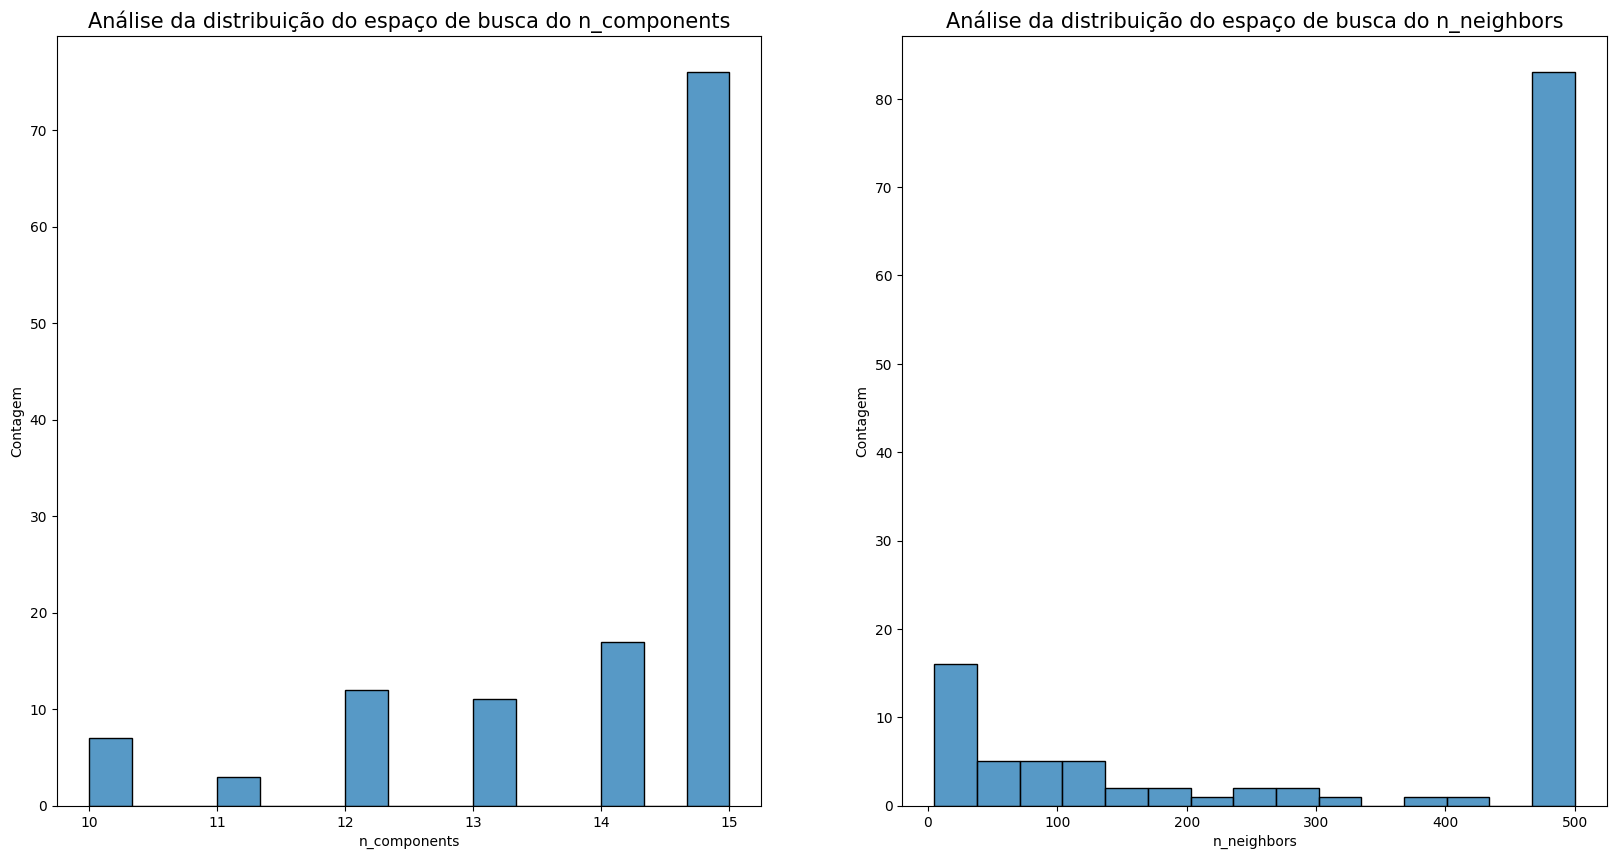

In [6]:
HYPERPARMS_ANALISYS = ["params_n_components", "params_n_neighbors"]

figs, axis = plt.subplots(ncols=len(HYPERPARMS_ANALISYS), figsize=(20, 10))

for hyperparam, ax in zip(HYPERPARMS_ANALISYS, axis):
    sns.histplot(
        df[hyperparam],
        bins=15,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}", size=15)
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

### Hiperparâmetro ``n_neighbors``

A partir dos gráficos, podemos ver com clareza que o buscador deu grande prioridade a valores de $k$ maiores, o que, para o dataset, faz sentido, tendo em vista a quantidade de dados. O teste foi feito com esse espaço de busca, justamente para testar o desempenho do algoritmo com $k$ pequeno, diante muitos dados. Com isso, uma boa proposta seria aumentar "deslocar" o espaço de busca, colocando agora como $k$ mínimo de 500 e um máximo que possa abranger mais exemplos, talvez 5000 - esse número não é arbitrário, uma vez que essa é, aproximadamente, a quantidade de YSOs Classe III, que é a classe minoritária e mais difícil de prever pelo seu menor emissão de IR. Porém, como isso aumentaria consideravelmente o tempo de otimização, isso ficará como proposta para uma análise futura.

### Hiperparâmetro ``n_components``

O resultado da otimização referente ao hiperparâmetro ``n_components``, do processo de PCA, foi interessante e vale certa atenção. Normalmente, algoritmos sensíveis a distância estão extremamente sujeitos à "maldição da dimensionalidade", ou seja, um número muito grande de atributos - e de dimensões, no caso desse algoritmo - pode afetar consideravelmente o desempenho do modelo, pois o aumento da dimensionalidade diminui exponencialmente a percepção de distância entre dois pontos. Porém, mesmo diante desse problema, foi visto que o valor mais usado pelo optuna foi o máximo do espaço de busca, o que sugere que o uso de mais atributos pode ajudar nesse problema.

Isso é interessante também pois existem alguns atributos no dataset que esperava-se ser mais úteis ou menos úteis, como a detecção de silicato, que continha pouquíssima informação. Nesse sentido, após fazer uma análise dos atributos, foram identificados 4 atributos principais que poderiam não ser usados, onde dois deles são referentes à posição e seria necessário fazer testes para determinar qual usar - isso porque foram usados dois sistemas de coordenada, então seria possível não usar um deles, descartando duas coordenadas.

Diante disso, uma ótima proposta é analisar o desempenho dos algoritmos com diferentes conjuntos de atributos, para testar a importância dos mesmos. Porém isso é uma proposta, novamente, de análise futura, pois não está no escopo deste trabalho.

## Análise **Árvore de Decisão**

Novamente, vamos carregar o arquivo da otimização.

In [3]:
NOME_DO_ESTUDO = "YSO_classifier-Tree"
objeto_de_estudo_Tree = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Tree.trials_dataframe()

Agora vamos ver qual foi o melhor modelo, sua estimativa de desempenho e seu conjunto de hiperparâmetros.

In [4]:
melhor_trial = objeto_de_estudo_Tree.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 101
Parâmetros do melhor trial: {'criterion': 'log_loss', 'max_depth': 29, 'min_samples_split': 0.0014037172376687068, 'mins_samples_leaf': 0.002548926681011357, 'min_weight_fraction_leaf': 0.0, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'n_components': 16}


101    0.872763
Name: value, dtype: float64

Com essa primeira análise, podemos ver que a árvore teve um melhor desempenho que o $k$-NN, mas ainda assim seria melhor fazer uma análise mais profunda. Além disso, é possível perceber, novamente, que um dos hiperparâmetros esteve no limite do espaço de busca, ``max_leaf_nodes``, ou seja, a limitação de nós do tipo folha. Isso deve ser um ponto de atenção, pois árvores muito fundas e, portanto, com mais nós folha tendem a ter *overfitting*. Para analisar de maneira mais profunda, vamos analisar a importância atribuida a cada hiperparâmetro.

In [9]:
vis.plot_param_importances(objeto_de_estudo_Tree)

Aqui vale algumas perceber uma coisa importante antes de continuar com a análise, pois essa importância atribuida pode não refletir tanto a importância dos atributos, mas a necessidade de limitá-lo ou de manipulá-lo com cuidado. Isso ficará mais claro mais adiante.

Mas, mesmo com essa questão, vamos fazer inicialmente uma análise dos hiperparâmetros de maior importância.

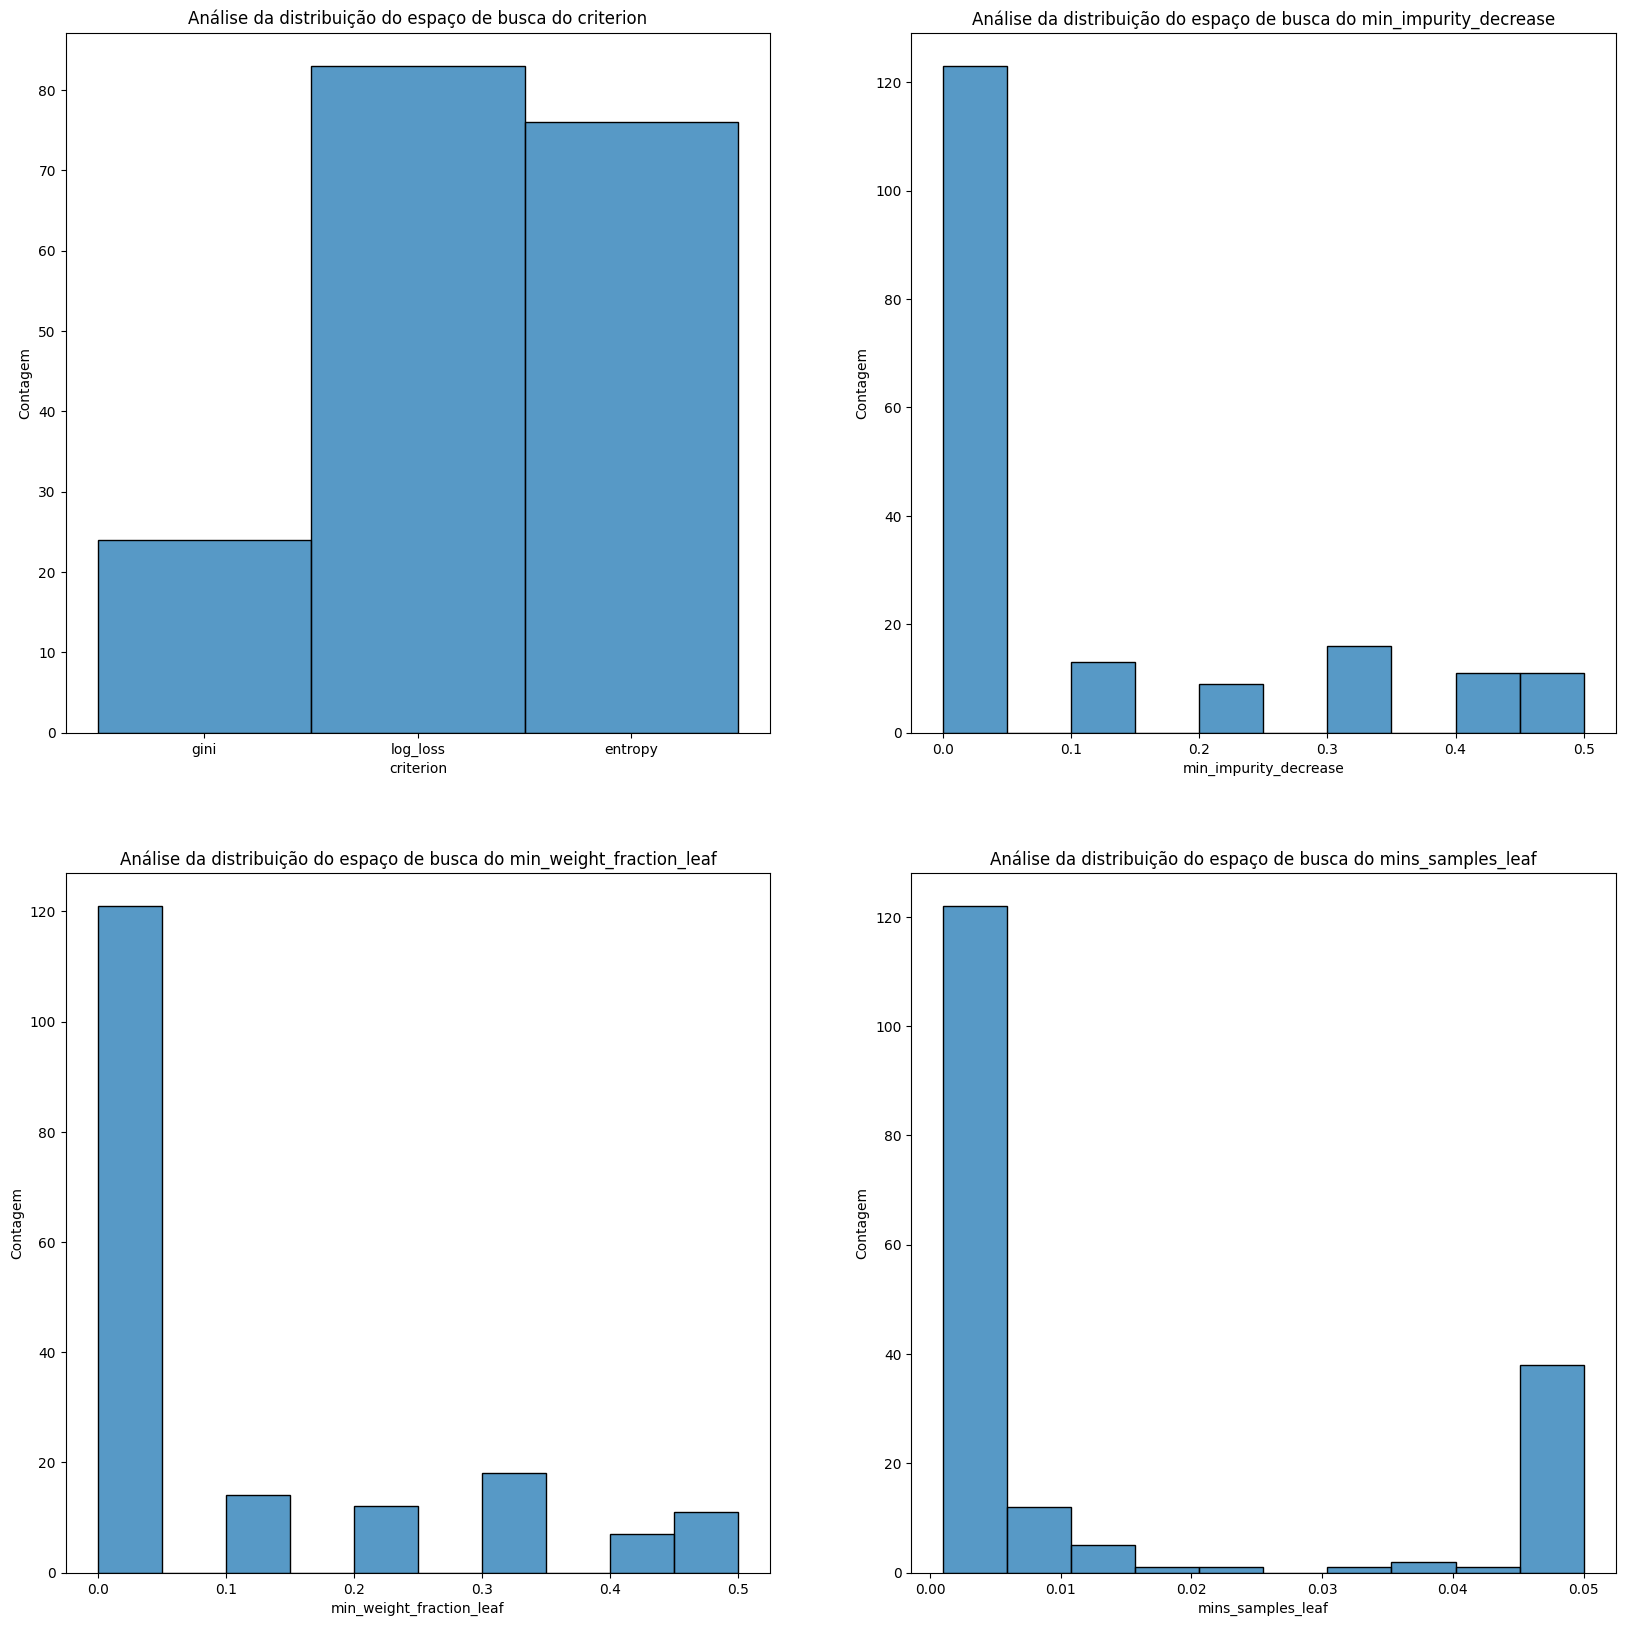

In [10]:
HYPERPARMS_ANALISYS = [
    "params_criterion", 
    "params_min_impurity_decrease",
    "params_min_weight_fraction_leaf",
    "params_mins_samples_leaf"
]

figs, axis = plt.subplots(nrows=2, ncols=2, figsize=(20, 20))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

Aqui entra a questão comentada anteriormente, pois uma coisa que fica clara no gráfico referente aos hiperparâmetros ``min_weight_fraction_leaf`` e ``min_impurity_decrease`` é que, na verdade, sua importância está em *não usá-lo*, definindo-o como 0. Isso significa que definir esses critérios de poda não são compensatórios para esse caso. Por esse motivo, não será feita uma discussão tão criteriosa quanto a esses hiperparâmetros.

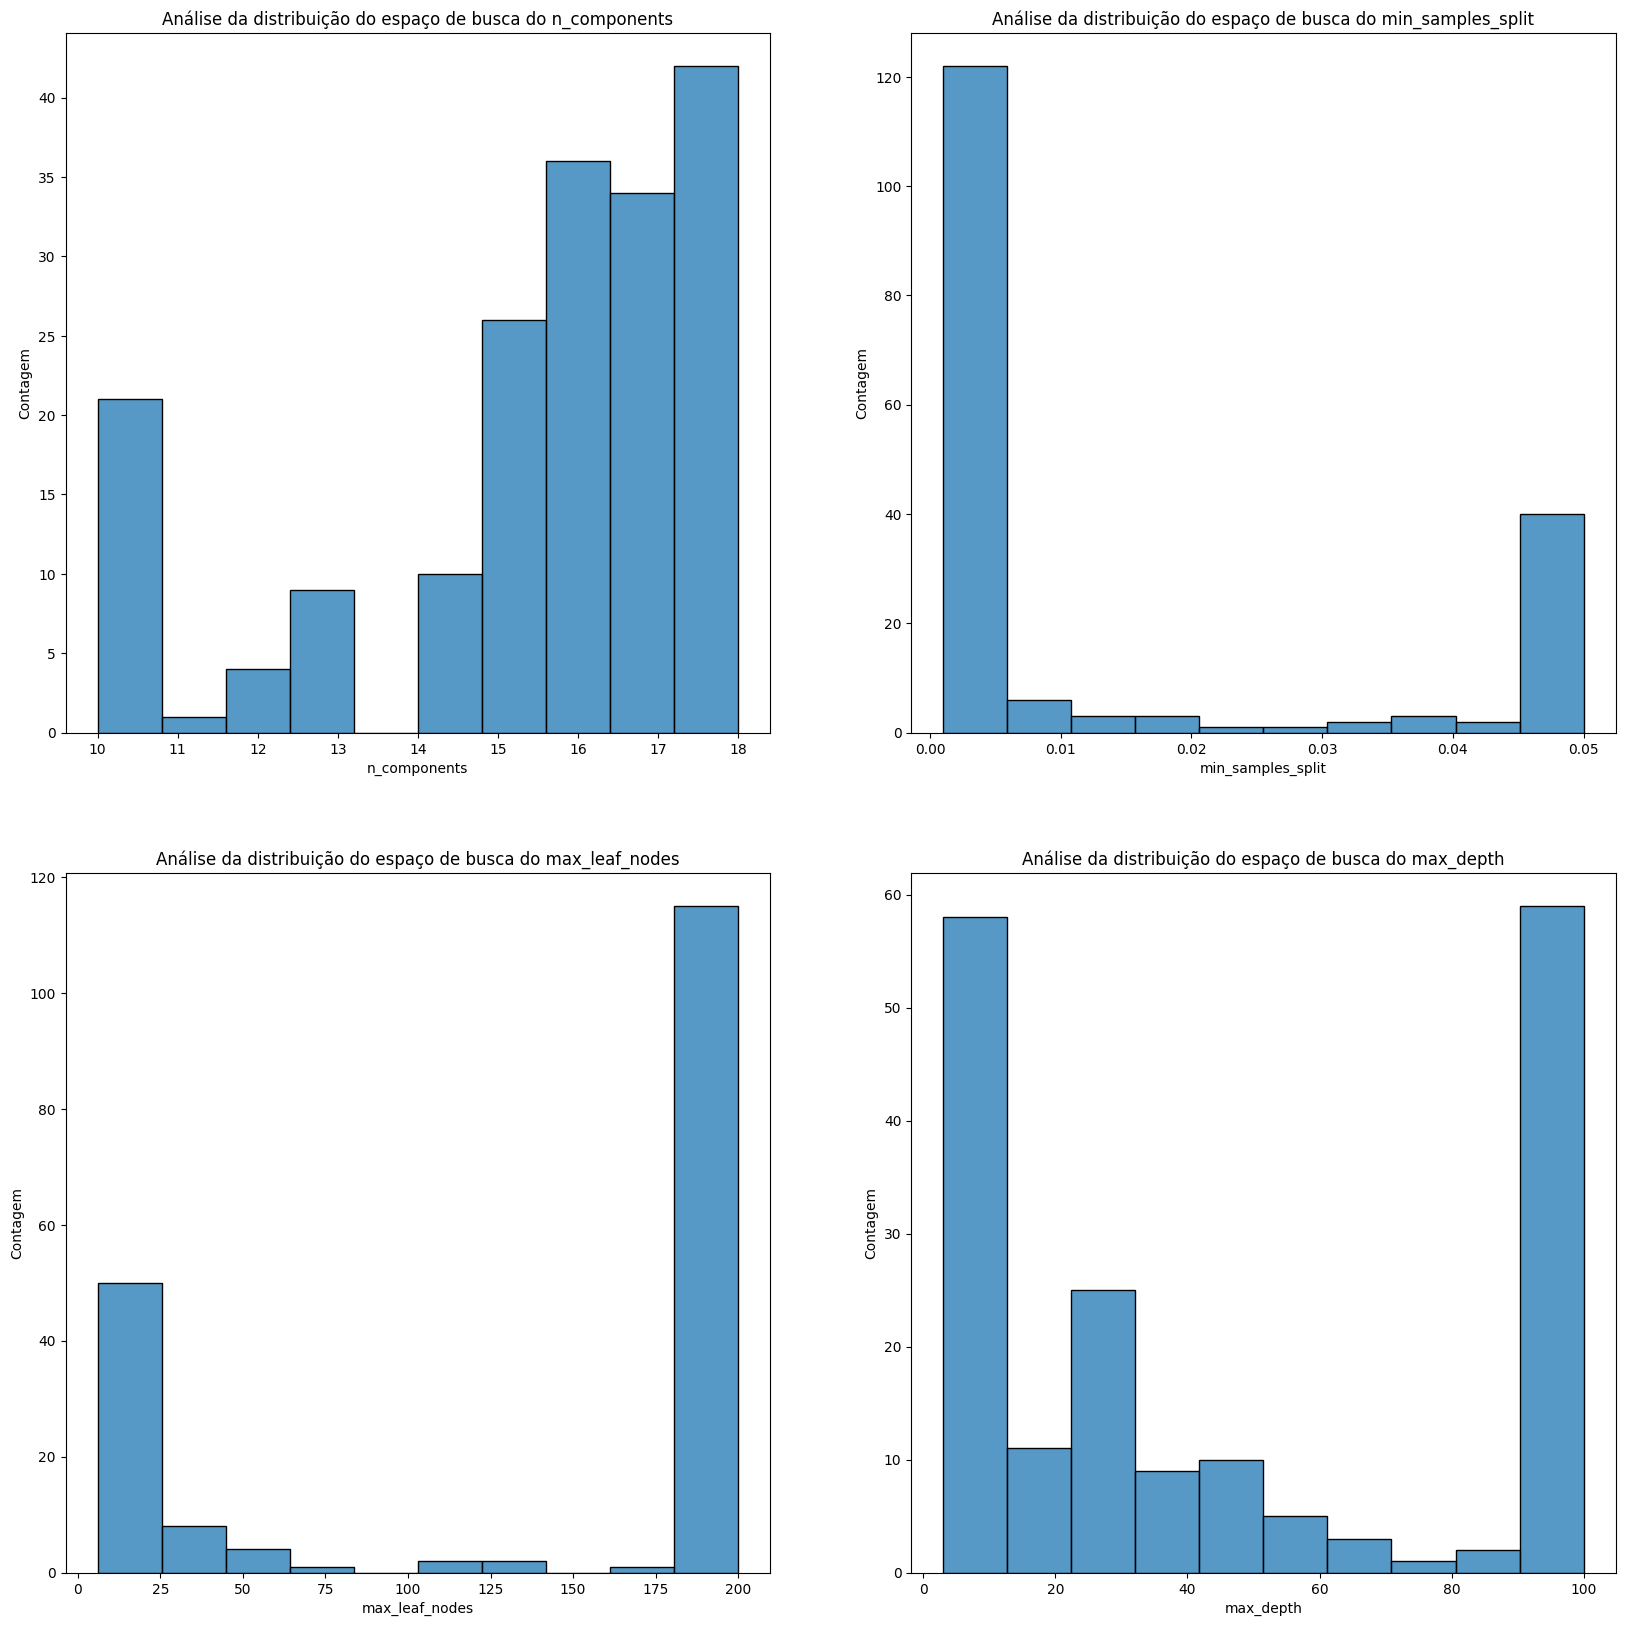

In [8]:
HYPERPARMS_ANALISYS = [
    "params_n_components",
    "params_min_samples_split",
    "params_max_leaf_nodes",
    "params_max_depth"
]

figs, axis = plt.subplots(nrows=2, ncols=2, figsize=(20, 20))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

Agora vamos analisar um a um.

### Hiperparâmetro ``criterion``

Pelo buscador, os critérios de divisão da árvore que tiveram melhor desempenho foram ``log_loss`` e ``entropy``. ``log_loss`` foi o que obteve melhor desempenho, mas como a diferença na quantidade de usos foi pequena, seria bom fazer uma segunda análise. Porém o critério ``gini``, que geralmente é o mais usado, foi o que menos foi usado, o que indica que teve menos desempenho, isso é interessante.

### Hiperparâmetro ``min_samples_leaf``

**Obs.:** No gráfico, e no arquivo de otimização, esse hiperparâmetro está marcado como ``mins_samples_leaf``, mas isso foi só um erro de digitação, o correto é ``min_samples_leaf``.

Esse foi outro hiperparâmetro que teve seu valor muito bem definido em um intervalo que representa um número mínimo de amostras bem pequeno. Na verdade, isso pode ter alguns motivos muito bons, primeiro porque esse espaço de busca foi definido como uma fração do total de amostras apresentadas para o algoritimo, ou seja, como o dataset é muito grande, mesmo uma fração pequena é um limite bem grande. Por esse motivo, seria interessante fazer uma segunda análise com um espaço de busca com frações menores. Mas isso só como aprofundamento e refinamento, pois pela quantidade de amostras, variar o limite de amostras por folha pode ser uma busca exaustiva demais para melhor pouco o desempenho do modelo. Por esse motivo, o arquivo de segunda otimização fixa esse valor para 0 - até porque limitar a quantidade de folhas já deixaria uma quantidade razoavelmente grande de amostras por folha.

### Hiperparâmetro ``n_components``

Aqui temos um resultado extremamente interessante, pois a busca mostra que um quantidades de atributos entre 15 e 18 tem bom desepenho - ou foi usada muitas vezes, pelo menos - o que pede uma análise mais profunda. Com isso em mente, e o fato de que o melhor modelo teve com valor de ``n_components`` 16, seria realmente interessante fazer uma análise humana e mais profunda a relevância dos atributos, uma vez que o de 16 pode refletir a análise prévia dos atributos, mas valores maiores podem significar que a árvore lida bem com uma grande quantidade de atributos, o que faz certo sentido com o algoritmo, que não sofre tanto com a maldição da dimensionalidade, mas consome mais recurso. Pensando nisso, e analisando os resultados da otimização do $k$-NN, será proposta uma análise mais profunda, tanto humana, quanto pela máquina, por PCA e o Optuna, por exemplo. Porém, pelo caráter complexo desse tipo de análise, isso será mais discutido do que realmente colocado em prática nesse momento.

### Hiperparâmetro ``min_samples_split``

Esse hiperparâmetro parece ser o mesmo caso do ``min_samples_leaf``, o que faz sentido, já que esse é um critério de poda relativamente parecido.

### Hiperparâmetro ``max_leaf_nodes``

Esse é outro caso que a busca teve grande prioridade para o limite do espaço de busca, o que significa que uma segunda análise, usando um espaço de busca deslocado, como no caso do $k$ do $k$-NN. Esse resultado, assim como alguns outros, apontam uma coisa interessante, árvores mais sensíveis, que geralmente sofreriam de *overfittinf* tem melhor desempenho que as menos sensíveis. Nesse caso, essa sensibilidade reflete, na verdade, a profundidade da árvore. Esses resultados podem ser reflexo de algumas características do próprio dataset, como número de amostras e sutileza de alguns atributos.

A luz disso, uma ou mais análises do funcionamento e resultado das árvores é recomendado, pois alguns dos atributos apresentam grande sutileza nos resultados, no sentido de que cada classe de YSO apresenta emissão de infravermelho em cada banda levemente diferente. Por isso, talvez o *overfitting* das árvores acabem fazendo com que elas captem melhor os padrões de cada classe, enquanto que árvores menos profundas e mais simples não consigam achar um padrão coerente. Mas isso é uma hipótese inicial, que pode não refletir a realidade desse algoritmo, então um próximo passo necessário para essa pesquisa é entender mais a fundo o funcionamento desse algoritmo e as sutilizas do dataset, buscando encontrar algo que possa melhor o desempenho dos modelos.

As questões propostas são importantes porque a maioria dos algoritmos testados e propostos usa de árvores de decisão como estimador, então isso pode ajudar não só a melhorar o desempenho de uma árvore de decisão, mas o desempenho de todos os outros modelos propostos.

### Hiperparâmetro ``max_depth``

Esse talvez seja o resultado mais intrigante e perigoso, pois a concentração de testes não está em uma região ou em *range* definido, mas *nos dois limites* do espaço de busca, o que pode significar que não foi possível definir um valor ou valores que dessem melhor desempenho de maneira satisfatíria, ou mesmo que os dois valores deram bons resultados. Mas o mais interessante é que valores baixos para ``max_depth`` refletem árvores mais simples e, teóricamente, com menos variância, que é a causa do *overfitting* usual desse algoritmo. Ou seja, a concentração de testes nos dois extremos do espaço de busca é *extremamente* contraditória, pois valores baixos resultam em árvores menores, enquanto que valores maiores resultam em árvores complexas.

Outro ponto importante é que este critério de poda é o mais simples e está intimamente ligado ao ``max_leaf_nodes``, uma vez que uma árvore com pequena profundidade simplesmente não conseguiria ter muitos nós folha, o que pode significar inclusive que vários testes com máximo de nós folha grande podem ser inconclusivos, uma vez que a limitação de profundidade não permitiria muitas folhas mesmo com ``max_leaf_nodes`` alto.

Por esses motivos, seria necessário um teste mais minuncioso para entender melhor a complexidade ótima das árvores. Porém, como esse foi o hiperparâmetro com menor importância atribuida, uma segunda análise inicial ótima seria fixando ``max_depth`` como alta e variando somente ``max_leaf_nodes`` para depois variar os dois juntos, com certo cuidado para não definir um conjunto contraditório. 

Agora vamos ver a otimização da floresta aleatória.

## Análise **Floresta Aleatória**

Vamos carregar o arquivo de otimização.

In [12]:
NOME_DO_ESTUDO = "YSO_classifier-Forest"
objeto_de_estudo_Forest = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Forest.trials_dataframe()

Analisar o melhor modelo.

In [13]:
melhor_trial = objeto_de_estudo_Forest.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 197
Parâmetros do melhor trial: {'n_estimators': 300, 'criterion': 'log_loss', 'max_depth': 53, 'min_samples_split': 0.0024193442436159273, 'mins_samples_leaf': 0.0010000000000000002, 'min_weight_fraction_leaf': 0.0, 'max_features': 0.5999999999999999, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'class_weight': 'balanced_subsample', 'n_components': 16}


197    0.894668
Name: value, dtype: float64

Como primeira análise, já podemos discutir algumas coisas. Primeiro, ``n_estimators`` está no limite do espaço de busca, segundo, ``min_samples_leaf`` está extremamente baixo novamente, terceiro, ``min_weigth_fraction_leaf`` e ``min_impurity_decrease`` novamente são zero, quarto, ``max_leaf_nodes`` está no limite e, por último, ``n_components`` é 16, assim como na análise anterior. Além disso, é importante notar que o melhor *trial* foi o de número 197, de um total de 200, ou seja, talvez expandir a busca seja interessante.

A partir disso, podemos reduzir nossa análise gráfica, pois muitos dos resultados são semelhantes ou identicos aos anteriores, o que pode indicar mesmo significado. Porém ainda é interessante discutir o porquê dessa semelhança.

Primeiro é importante deixar claro que, mesmo que as florestas aleatórias sejam baseadas em árvores de decisão, os os dois algoritmos são bem diferentes em muitos sentidos. Porém, mesmo assim, alguns dos resultados apresentados fazem muito sentido, como ``min_weight_fraction_leaf`` e ``min_impurity_decrease`` serem zero, já que seu funcionamento continua o mesmo. A partir disso, conclui-se que não será de grande ajuda variar os dois hiperparâmetros comentados agora e nem ``min_samples_leaf``, que tiveram resultados muito semelhantes aos anteriores, indicando as mesmas questões. Outra coisa importante de se notar é que ``n_components`` foi novamente 16, algo que pode refletir realmente os quatro atributos comentados anteriormente.

Outro ponto de atenção é que esse *trial* estava no fim da busca, e que seu resultado, mesmo que melhor, foi muito próximo da árvore, o que pode significar uma flutuação de acaso. Por esse motivo, uma análise mais profunda dos hiperparâmetros mais relevantes e uma busca mais minunciosa é interessante.

Agora vamos visualizar a importância atribuida a cada hiperparâmetro.

In [14]:
vis.plot_param_importances(objeto_de_estudo_Forest)

É importante ressaltar que os hiperparâmetros ``min_impurity_decrease``, ``min_samples_split`` e ``min_weight_fraction_leaf`` podem ser os de maior importância, mas de novo é só um indicativo de que devem ser definidos como 0 ou deixados em valores baixos. Porém, ainda assim, vamos analisar um pouco ``min_samples_split`` para ter certeza, já que houve grande diferença na importância entre ele e ``min_samples_split``.

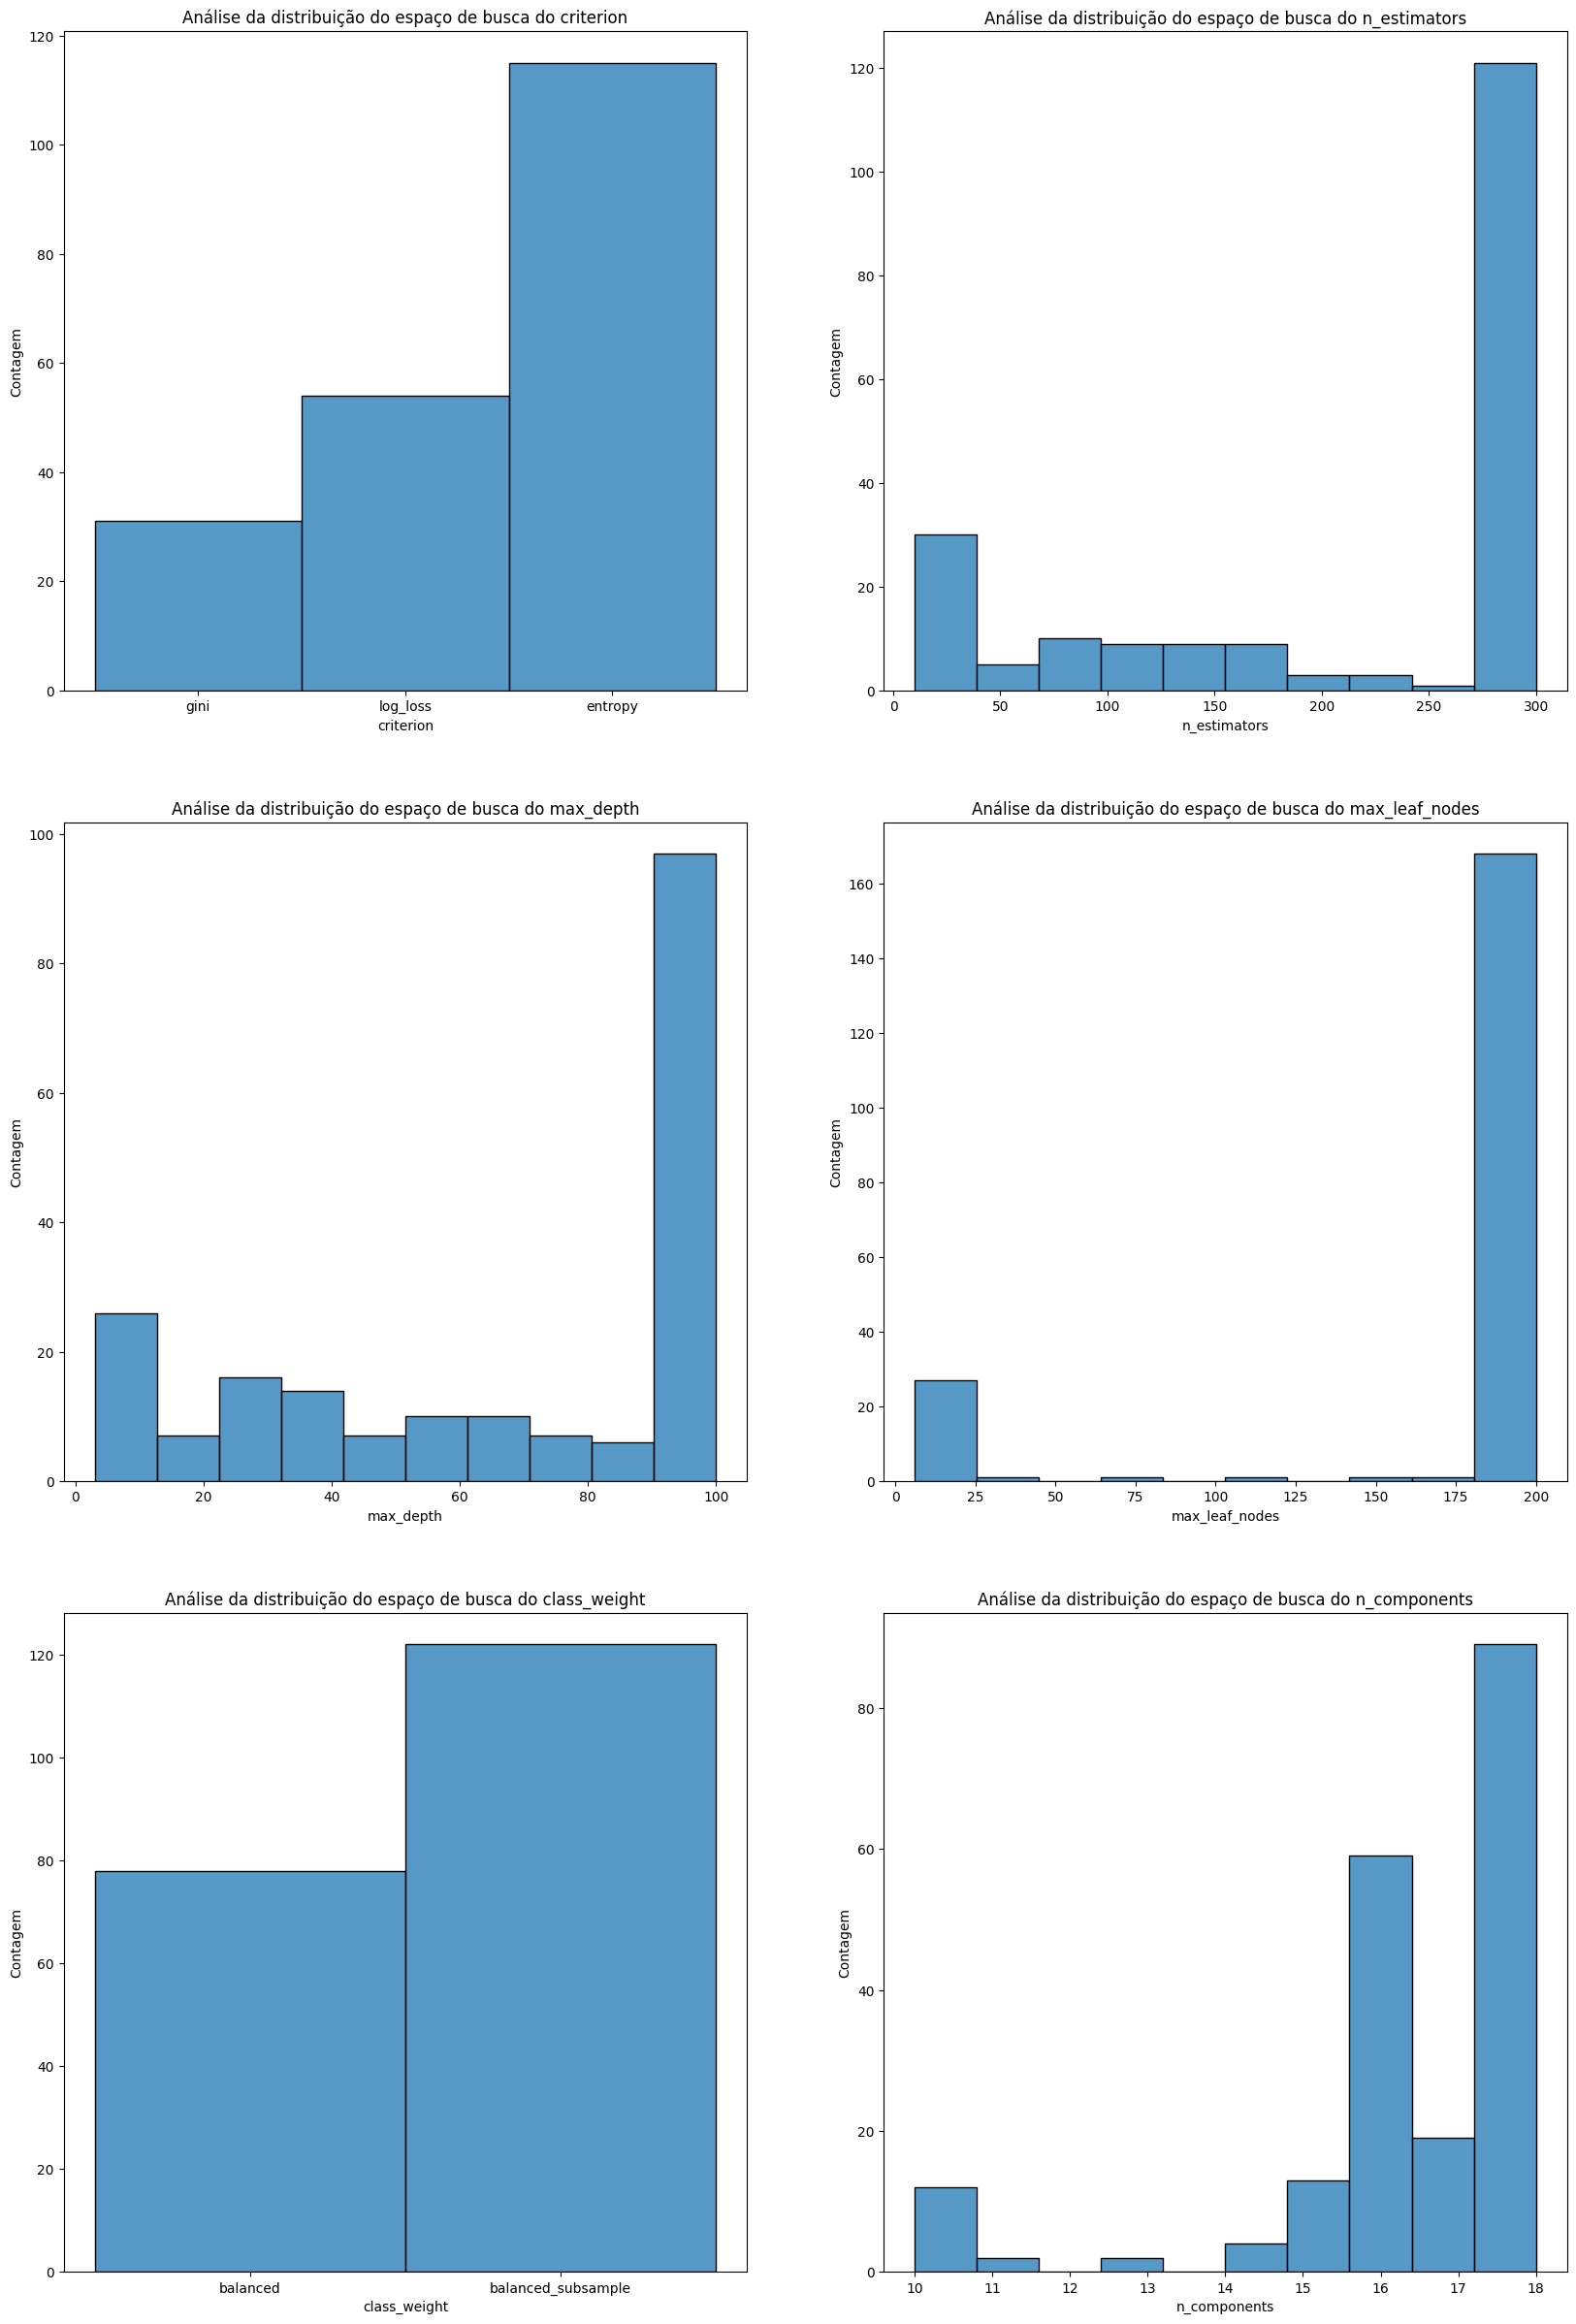

In [14]:
HYPERPARMS_ANALISYS = [
    "params_criterion",
    "params_n_estimators",
    "params_max_depth",
    "params_max_leaf_nodes",
    "params_class_weight",
    "params_n_components"
]

figs, axis = plt.subplots(nrows=3, ncols=2, figsize=(20, 30))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

### Hiperparâmetro ``criterion``

Algo interessante aconteceu com esse hiperparâmetro, pois enquanto a busca na árvore foi mais voltada para ``log_loss``, no caso da floresta foi ``entropy``. Porém, mesmo assim, o melhor modelo ainda usa ``log_loss``. Por esse motivo, seria interessante entender mais sobre esse critério e entender se o melhor modelo nesse caso só usou ``log_loss`` por conhecidência ou realmente porque ele foi relevante para esse resultado. Além disso, esse resultado indica que a busca no caso da árvore talvez tenha sido um pouco rasa, uma vez que foram realizados 100 *trials* ao invés de 200, como no caso da floresta.

### Hiperparâmetro ``n_estimators``

Este foi outro hiperparâmetro que teve grande concentração no limite do espaço de busca. Por esse motivo, também seria interessante alterar o espaço de busca, desclocando-o. Isso talvez aconteça pela grande sutileza dos dados, fazendo com que seja mais difícil encontrar seus padrões. Além disso, caso o número ótimo de estimadores seja grande demais, ao passo que o ganho na ROC-AUC em relação à árvore seja pequeno, compensaria mais usar uma árvore mais complexificada, para diminuir o custo computacional, que poderia aumentar muito para ganhar pouco desempenho.

### Hiperparâmetro ``max_depth``

Aqui houve uma coisa interessante em comparação com os resultados da árvore, uma vez que, no caso da floresta aleatória, a maior concentração dos valores foi somente no limite superior do espaço de busca, ou seja, somente com árvores *mais complexas*. Isso pode ser decorrente de diversas coisas, mas a hipótese levantada aqui é que, graças as sutilezas dos dados e a maneira como a floresta aleatória funciona, deixar as árvores extremamente complexas, aproveitando do *overfitting*, pode fazer com que a variabilidade das árvores aumente ao ponto do algoritmo conseguir entender melhor os padrões dos dados. Outro ponto importante é que a otimização da árvore usou somente metade da quantidade de *trials* em comparação da floresta, ou seja, talvez aumentar o número de *trials* possa mostrar melhor como seria a complexidade ótima da mesma - fora, claro, as possíveis contradições quanto aos hiperparâmetros ``max_depth`` e ``max_leaf_nodes``. Por esse motivo, uma melhor análise das **árvores** pode ajudar a entender melhor o porquê desse resultado da floresta e, caso **árvores** mais simples sejam melhores que **florestas** muito profundas e com muitas árvores - ou o ganho de precisão seja pequeno -, talvez seja mais compensatório investir em uma boa árvore mais simples - ou mesmo mais complexa.

### Hiperparâmetro ``max_leaf_nodes``

Esse resultado foi extremamente semelhante com o da árvore, o que talvez signifique que manter o número máximo de vértices folha pode ser mais vantajoso. Novamente vale ressaltar que, no caso da árvore, parte dos resultados são inconclusivos, pois pode ter havido contradição em alguns *trials*, logo seria necessário uma melhor análise, porém ainda é possível ver grande semelhança nos resultados, uma vez que uma parte considerável dos testes ainda assim usou um valor grande de ``max_depth``.

### Hiperparâmetro ``class_weight``

Como a distribuição foi relativamente parecida entre os dois métodos, valeria a pena continuar trabalhando neles em uma segunda otimização, pois sua importância foi relativamente pequena, o que significa que, talvez, só escolher o que foi melhor seja uma estratégia simples e eficiente.

### Hiperparâmetro ``n_components``

Esse foi um resultado interessante, uma vez que, diferente da otimização da árvore, os valores mais usados ficaram muito concentrados em 16 e 18, que era o valor máximo. Isso, na verdade, faz sentido pois, como já foi dito, árvores lidam bem com altas dimensionalidades. Porém, como os resultados das duas otimizações mostram que 16 é um bom valor, retirar 4 dos 20 atributos pode ser uma boa estratégia para deixar a compreensibilidade e aplicabilidade mais simples, além de deixar mais barato computacionalmente. Além disso, mesmo que muitos *trials* tivessem usado 18 como valor de ``n_components``, a importância atribuida ao hiperparâmetro foi a menor, logo usar essa estratégia pode ser interessante por não alterar muito o desempenho do modelo, mas melhorar sua aplicabilidade.

Agora vamos verificar o desempenho do Classificador Naive-Bayes, que foi o mais simples.

## Análise **Naive-Bayes Gaussiano**

Vamos carregar o arquivo da otimização.

In [16]:
NOME_DO_ESTUDO = "YSO_classifier-Naive_Bayes"
objeto_de_estudo_NB = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_NB.trials_dataframe()
df

,number,value,datetime_start,datetime_complete,duration,params_n_components,params_var_smoothing,system_attrs_fixed_params,system_attrs_gp:relative_params:0,state
0,0,0.630572,2026-10-27 12:02:20.920826,2026-10-27 12:02:24.391435,0 days 00:00:03.470609,18,1.000000e-09,{'var_smoothing': 1e-09},NaN,COMPLETE
1,1,0.642167,2026-10-27 12:02:24.500885,2026-10-27 12:02:28.039219,0 days 00:00:03.538334,14,1.177832e-08,NaN,NaN,COMPLETE
2,2,0.672232,2026-10-27 12:02:28.257019,2026-10-27 12:02:31.745330,0 days 00:00:03.488311,14,1.487969e-05,NaN,NaN,COMPLETE
3,3,0.679138,2026-10-27 12:02:31.885259,2026-10-27 12:02:35.308444,0 days 00:00:03.423185,18,3.443575e-05,NaN,NaN,COMPLETE
4,4,0.663338,2026-10-27 12:02:35.503208,2026-10-27 12:02:38.850802,0 days 00:00:03.347594,18,2.509584e-06,NaN,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...
395,395,0.691602,2026-10-27 16:18:39.509892,2026-10-27 16:18:46.153469,0 days 00:00:06.643577,15,1.000000e-04,NaN,"{""n_components"": 15, ""var_smoothing"": 0.0001}",COMPLETE
396,396,0.691602,2026-10-27 16:18:46.723155,2026-10-27 16:18:52.808705,0 days 00:00:06.085550,13,1.000000e-04,NaN,"{""n_components"": 13, ""var_smoothing"": 0.0001}",COMPLETE
397,397,0.691602,2026-10-27 16:18:53.369205,2026-10-27 16:18:59.033550,0 days 00:00:05.664345,18,1.000000e-04,NaN,"{""n_components"": 18, ""var_smoothing"": 0.0001}",COMPLETE
398,398,0.691602,2026-10-27 16:18:59.507267,2026-10-27 16:19:05.163417,0 days 00:00:05.656150,16,1.000000e-04,NaN,"{""n_components"": 16, ""var_smoothing"": 0.0001}",COMPLETE


Uma coisa interessante de se notar é que essa foi a otimização mais rápida, e usou o dobro de *trials*.

Agora vamos ver o melhor *trial*.

In [17]:
melhor_trial = objeto_de_estudo_NB.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 10
Parâmetros do melhor trial: {'var_smoothing': 0.0001, 'n_components': 10}


10    0.691602
Name: value, dtype: float64

Esse foi, sem dúvidas, o pior resultado, pois mesmo com uma busca bem maior que as outras, ele obteve um desempenho baixíssimo, além de que, se analisarmos, todos os *trials* a partir disso tiveram o mesmo desempenho. Isso pode refletir duas coisas, primeiro, a utilização de atributos discretos e, segundo, não usar as cores mencionadas no arquivo principal. Dessa maneira, uma segunda otimização levando isso em conta valeria a pena, pelo poder preditivo e baixo custo computacional desse algoritmo.

## Análise **Gradient Boosting por Histograma**

Vamos carregar o arquivo de otimização.

In [1]:
NOME_DO_ESTUDO = "YSO_classifier-Hist_Gradient_Boosting"
objeto_de_estudo_Hist_Gradient_Boosting = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Hist_Gradient_Boosting.trials_dataframe()

NameError: name 'load_study' is not defined

Agora vamos ver o melhor *trial*.

In [19]:
melhor_trial = objeto_de_estudo_Hist_Gradient_Boosting.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 152
Parâmetros do melhor trial: {'learning_rate': 0.01, 'max_iter': 100, 'max_leaf_nodes': 150, 'max_depth': 7, 'min_samples_leaf': 150, 'l2_regularization': 0.0, 'max_features': 0.5998139955941242, 'max_bins': 100, 'n_components': 17}


152    0.88174
Name: value, dtype: float64

Como é possível perceber, a floresta aleatória foi melhor, por pouco, em relação ao Gradient Boosting por Histograma. Além disso, o máximo de iterações foi um número razoável. Agora, o que foi mais interessante foi a profundidade, uma profundidade baixíssima em comparação as com as outras otimizações. A partir disso, vamos ver a importância de hiperparâmetros.

In [20]:
vis.plot_param_importances(objeto_de_estudo_Hist_Gradient_Boosting)

Com isso, é possível perceber que o que mais influenciou na otimização foi ``n_components`` e ``learning_rate``, enquanto os outros contribuiam pouco. Com isso, conseguimos inferir que, mesmo com um poder preditivo menor que a árvore, o ganho computacional pode melhorar.

Agora vamos plotar alguns gráficos.

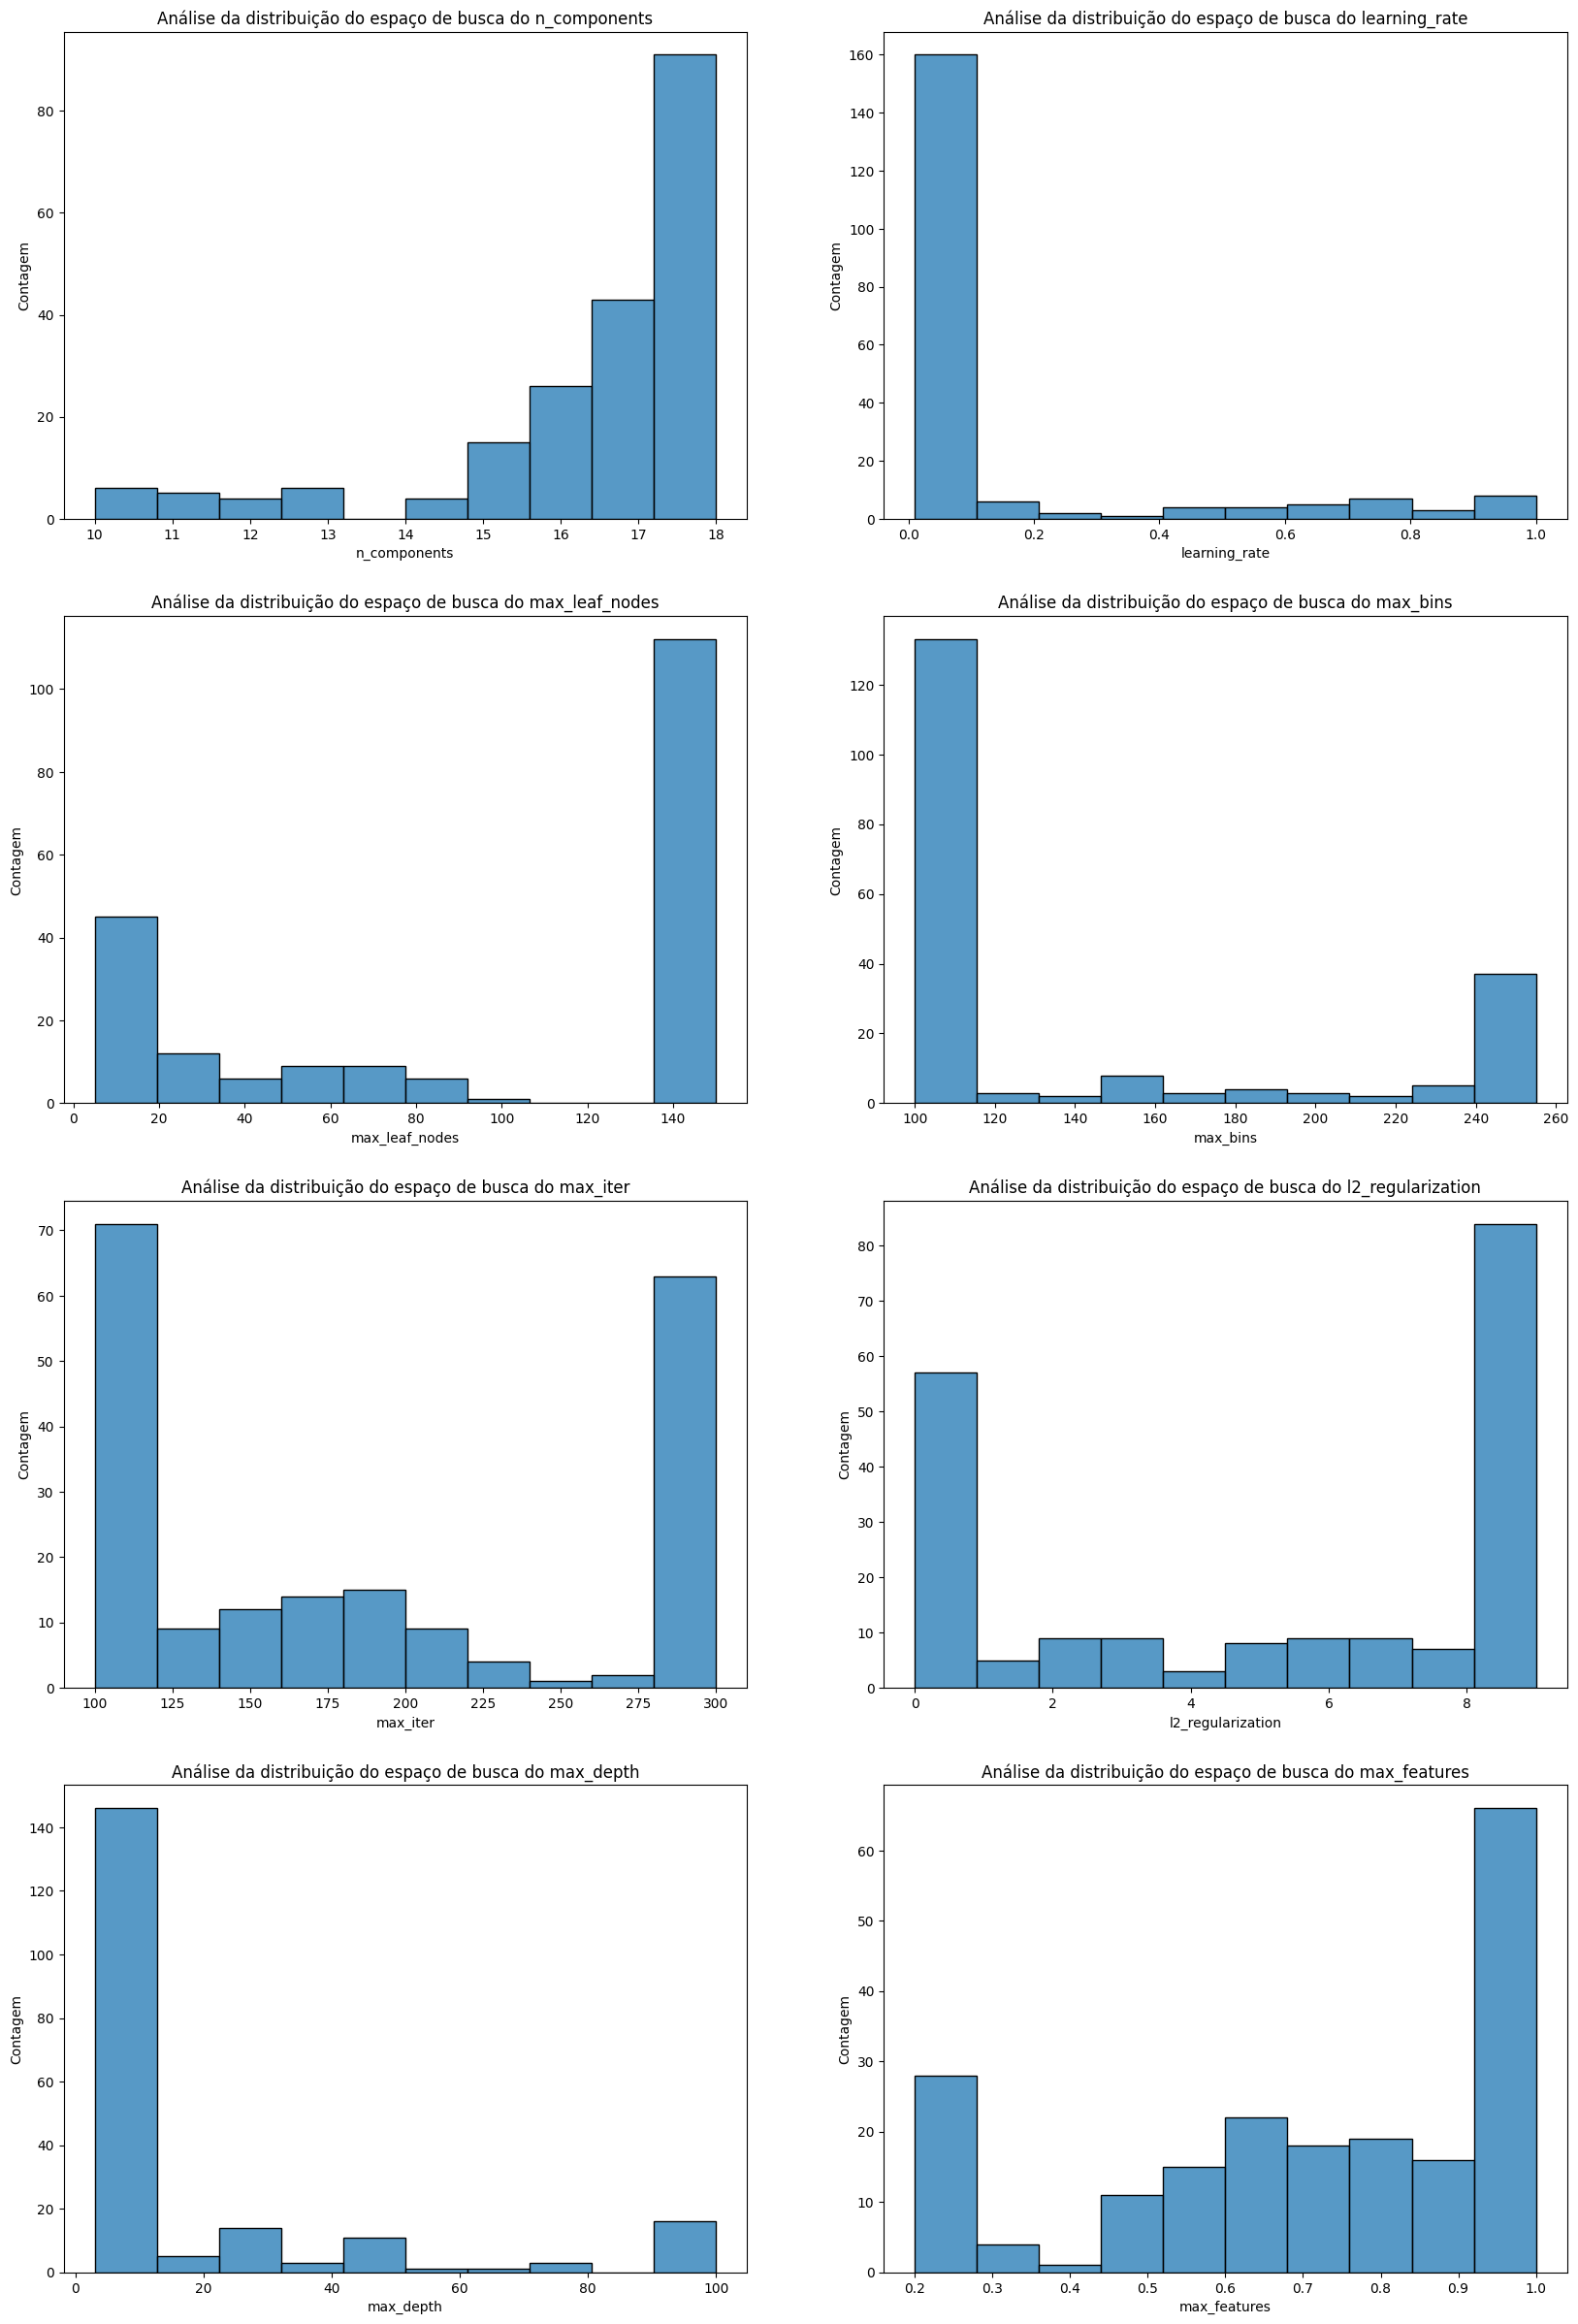

In [21]:
HYPERPARMS_ANALISYS = [
    "params_n_components",
    "params_learning_rate",
    "params_max_leaf_nodes",
    "params_max_bins",
    "params_max_iter",
    "params_l2_regularization",
    "params_max_depth",
    "params_max_features"
]

figs, axis = plt.subplots(nrows=4, ncols=2, figsize=(20, 30))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1],
    [3,0], [3,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

### Hiperparâmetro ``n_components``

Vemos aqui que o número ótimo de atributos se aproxima dos vistos anteriormente, o que torna o raciocínio ainda mais condizente.

### Hiperparâmetro ``learning_rate``

Aqui parece que vemos algo semelhante ao ``min_weight_fraction_leaf``, onde o valor mínimo foi o melhor e valores mais altos podem afetar muito o desempenho do modelo.

### Hiperparâmetro ``max_leaf_nodes``

Vemos aqui algo semelhante ao anterior, onde os melhores valores se concentram no limite do espaço de busca, o que pode significar que realmente árvores mais complexas podem ser melhores.

### Hiperparâmetro ``max_bins``

Esse foi um resultado interessante, pois vemos que os valores se concentraram em valores mais baixos do espaço de busca, o que pode significar que discretizar os atributos pode ser muito mais benéfico para esse algoritmo que deixar o mais informativo possível.

### Hiperparâmetro ``max_iter``

Aqui vemos algo interessante novamente, os *trials* se concentram em ambos os limites do espaço de busca, mas o valor usado no melhor modelo foi de 100. Porém, mesmo que esse resultado seja interessante ou contraditório, a importância atribuida a esse hiperparâmetro foi a menor, o que pode significar que esse resultado seja simplesmente resultado da própria configuração do GPSampler.

### Hiperparâmetro ``l2_regularization``

Aqui vemos novamente concentrações divergentes, mas, nesse caso, a importância não foi tão menor quanto em ``max_iter``. Ainda assim, como seu valor foi de 0.0 no melhor *trial*, seria melhor fazer uma análise mais profunda.

### Hiperparâmetro ``max_depth``

Aqui as coisas ficam extremamente diferentes em comparação aos outros resultados, uma vez que a profundidade máxima, nesse caso, acaba sendo extremamente menor. Isso talvez se traduza no contexto do algoritmo, que, ao invés de usar somente uma camada com várias árvores, a fim de reduzir variância, ele usa diversas camadas usando uma árvore em cada, que irá entregar para a árvore da camada seguinte, as probabilidades atribuidas a cada exemplo. Com isso, árvores mais simples talvez tendam a encontrar padrões mais facilmente e sem grande necessidade de grande complexidade.

### Hiperparâmetro ``max_features``

Esse resultado é interessante pois se assemelha muito aos resultados dos outros algoritmos, o que pode dizer que valores entre 0.4 e 0.7 são valores ótimos para esse atributo.

# Análise de segunda otimização

Após uma análise mais profunda do algoritmo *Gaussian Naive-Bayes*, e de previsão de YSOs, através do Claude [Conversa 3], percebeu-se que adicionar os atributos referentes às cores de cada YSO, calculadas pela diferença entre as magnitudes de faixas adjascentes. Com isso, foi aplicado parte das recomendações ditas anteriormente e feitas segundas otimizações usando o dataset com os atributos de cores, e retirando certos atributos que foram considerados ruins. Por esse motivo, será feita uma segunda análise, com novas otimizações.

## Análise **k-NN**

Não foi possível concluir a otimização, mas foram realizados 40 *trials*, com desempenho semelhante ao anterior, mas ainda assim analisaremos seu desempenho.

In [35]:
NOME_DO_ESTUDO = "YSO_classifier-kNN_v2"
objeto_de_estudo_kNN = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_kNN.trials_dataframe()

In [37]:
melhor_trial = objeto_de_estudo_kNN.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 29
Parâmetros do melhor trial: {'n_neighbors': 500, 'weights': 'distance', 'p': 1.1900000000000002, 'n_components': 14}


29    0.883715
Name: value, dtype: float64

## Análise **Árvore de Decisção**

Vamos primeiro carregar o estudo.

In [4]:
NOME_DO_ESTUDO = "YSO_classifier-Tree_v2"
objeto_de_estudo_Tree = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Tree.trials_dataframe()

In [5]:
melhor_trial = objeto_de_estudo_Tree.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 81
Parâmetros do melhor trial: {'criterion': 'log_loss', 'max_depth': 300, 'min_samples_split': 0.0010000000000000002, 'min_samples_leaf': 0.0010000000000000002, 'min_weight_fraction_leaf': 0.0, 'max_leaf_nodes': 500, 'min_impurity_decrease': 0.0, 'n_components': 14}


81    0.891081
Name: value, dtype: float64

Interessante, já notamos uma melhora, mesmo que pequena. Mas, se considerarmos que temos 100 mil exemplos, acertar em mais 2% é muito bom. Além disso, podemos perceber que muitos dos valores foram muito semelhantes ao anterior, com a diferença do ``n_components``. Isso talvez se resuma à utilização de atributos mais significativos e à adição das cores. Mas vamos analisar os outros.

## Análise **Floresta Aleatória**

Vamos primeiro carregar o arquivo do estudo.

In [9]:
NOME_DO_ESTUDO = "YSO_classifier-Forest_v2"
objeto_de_estudo_Forest = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Forest.trials_dataframe()

In [10]:
melhor_trial = objeto_de_estudo_Forest.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 163
Parâmetros do melhor trial: {'n_estimators': 500, 'criterion': 'entropy', 'max_depth': 92, 'min_samples_split': 0.0010000000000000002, 'min_samples_leaf': 0.0010000000000000002, 'min_weight_fraction_leaf': 0.0, 'max_features': 0.6499999999999999, 'max_leaf_nodes': 500, 'min_impurity_decrease': 0.0, 'class_weight': 'balanced_subsample', 'n_components': 16}


163    0.911715
Name: value, dtype: float64

Continuamos vendo melhora, o que pode significar realmente que as cores aumentam o poder de predição consideravelmente. Além disso, vemos uma profundidade maior ainda em comparação à otimização anterior, ``max_features`` se mantém no intervalo da hipótese proposta, o máximo de folhas ainda está bem alto e, algo ainda mais interessante, ``n_components`` continua em 16, mesmo com a mudança de *features* utilizados.

Vamos analisar a importância de cada atributo para poder avaliar isso melhor.

In [11]:
vis.plot_param_importances(objeto_de_estudo_Forest)

Agora vemos que a importância dos hiperparâmetros aumentou um tanto interessante. Outra coisa que podemos notar é que, ignorando os dois mais importantes, definidos como 0.0 ao final, a maioria tem mesma importância. Isso também mostra o poder de predição da floresta e o aumento no mesmo com as cores.

Agora vamos ver os hiperparâmetros.

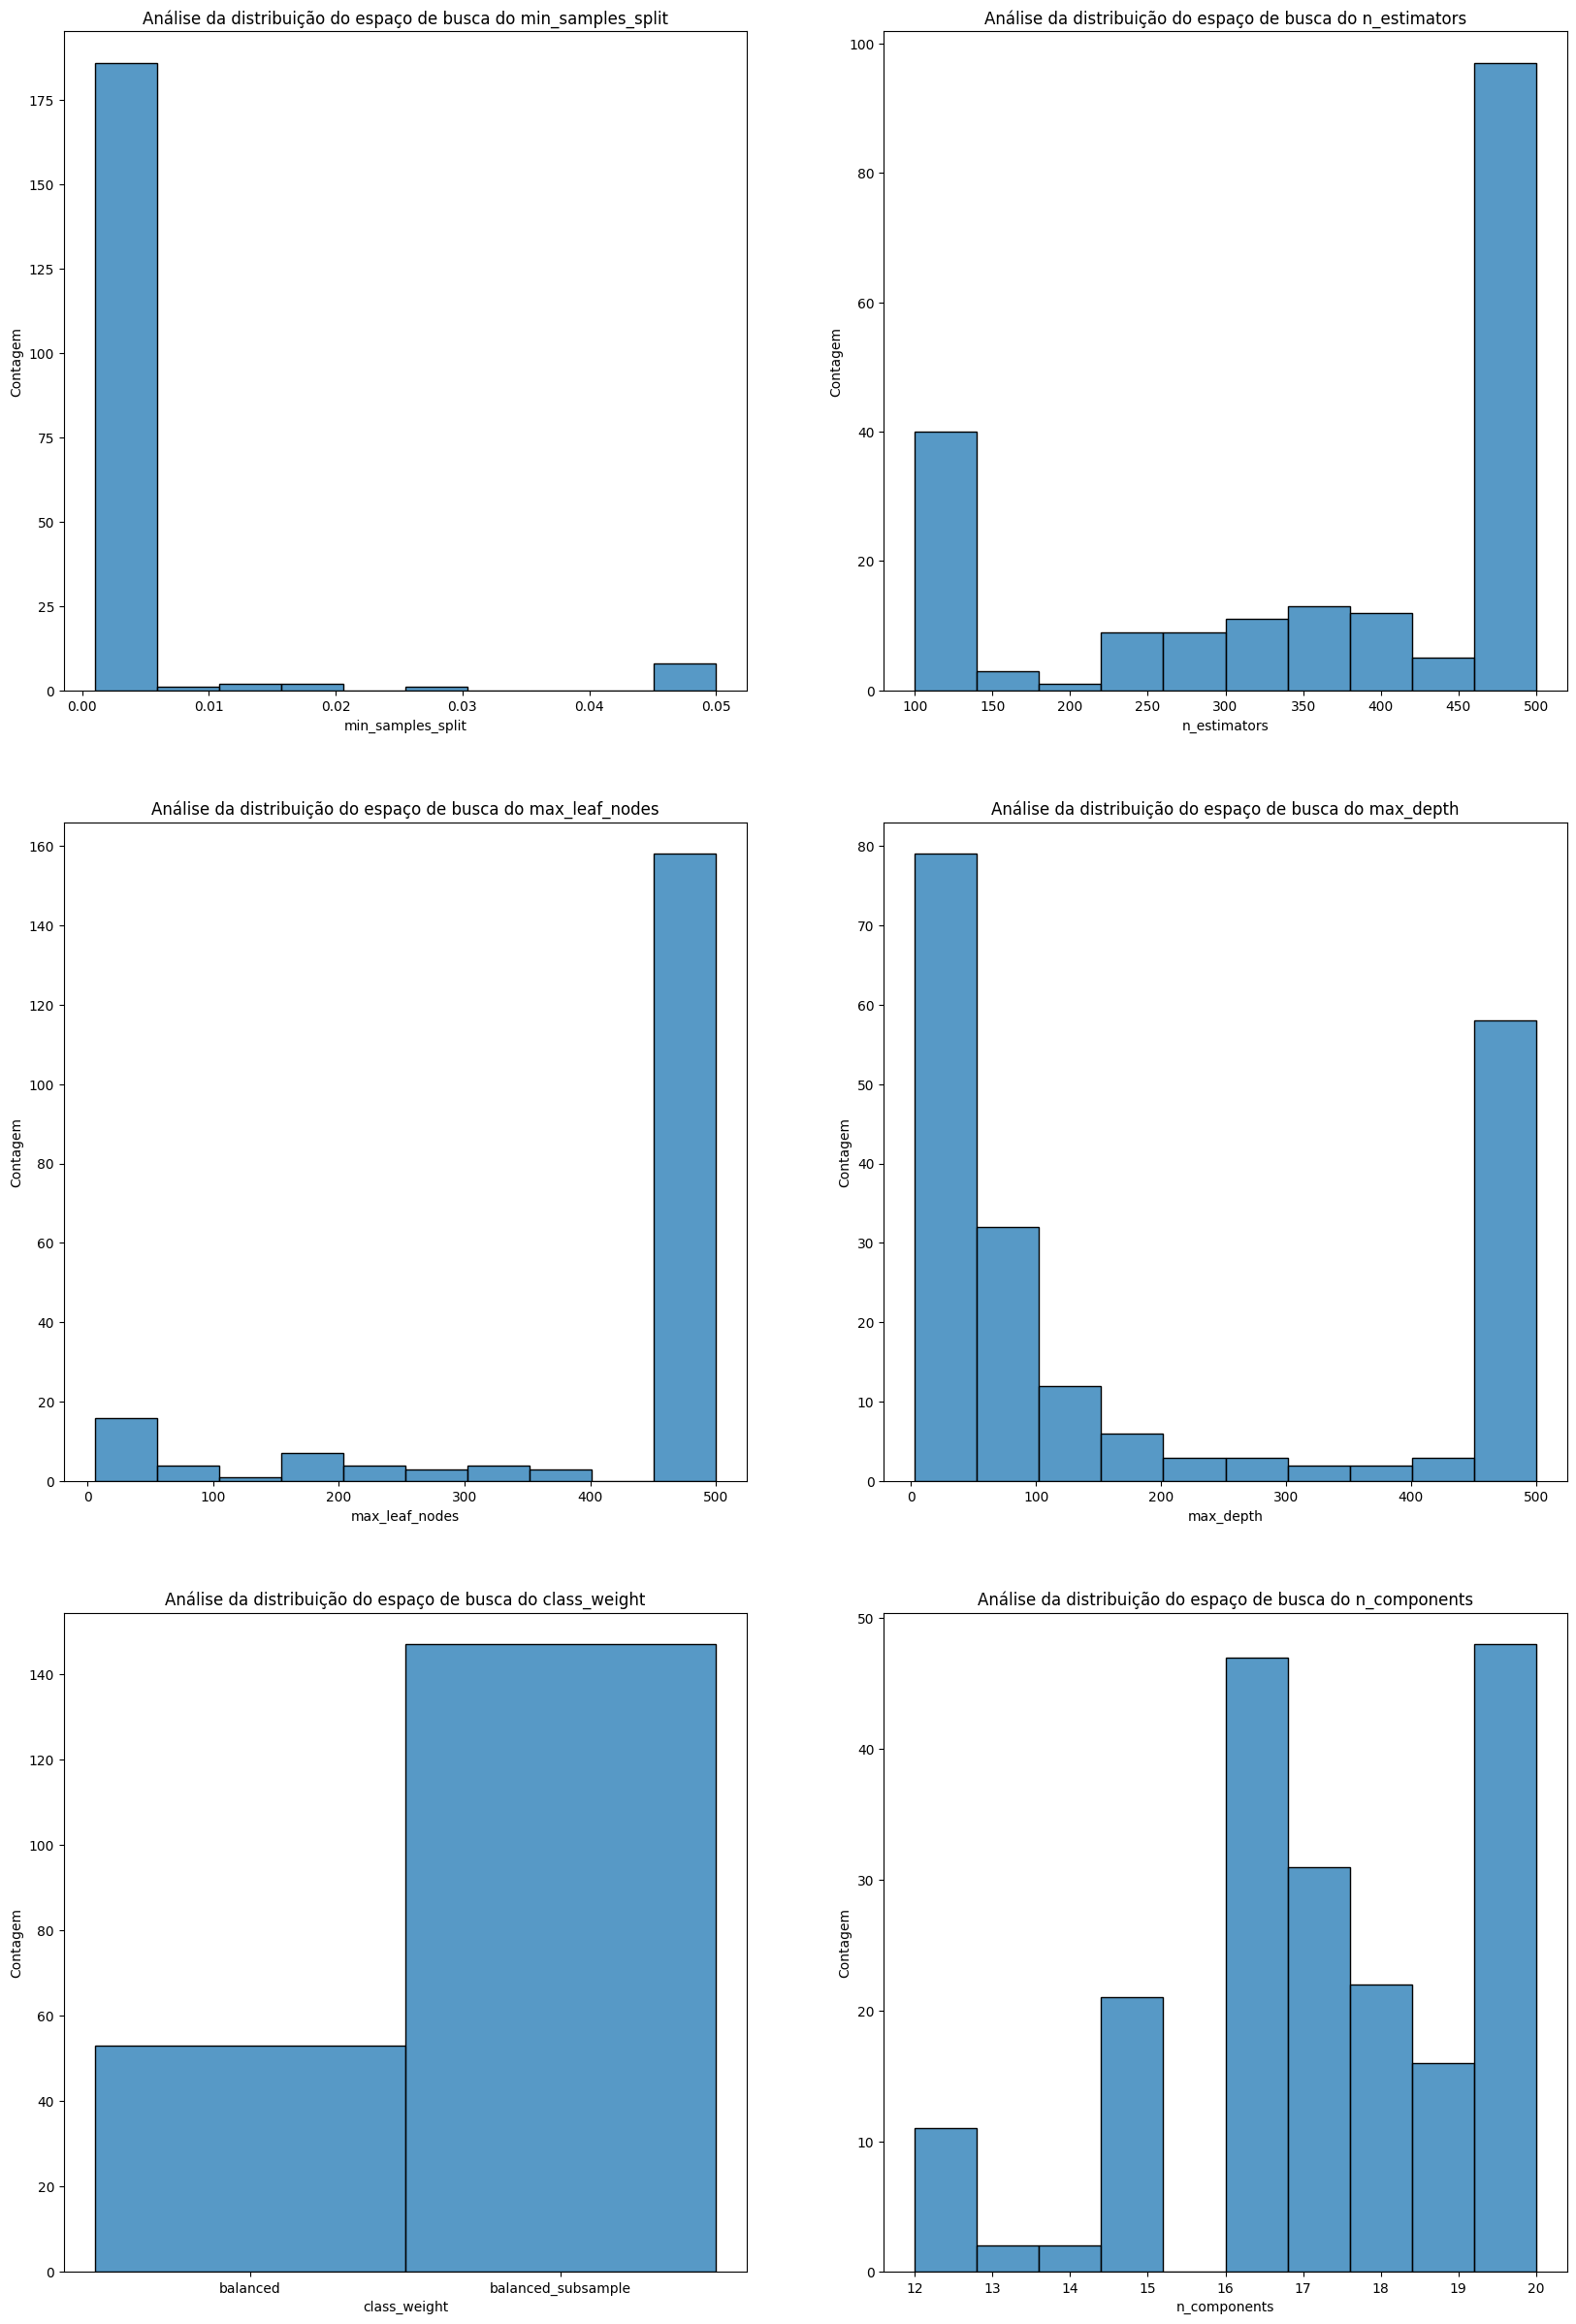

In [14]:
HYPERPARMS_ANALISYS = [
    "params_min_samples_split",
    "params_n_estimators",
    "params_max_leaf_nodes",
    "params_max_depth",
    "params_class_weight",
    "params_n_components"
]

figs, axis = plt.subplots(nrows=3, ncols=2, figsize=(20, 30))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

Vemos que o ``min_samples_split`` e ``max_leaf_nodes`` tiveram o mesmo efeito de antes, o que pode significar que realmente não definir valor mínimo de amostras por folha e talvez **não definir um máximo de folhas** faça a floresta trabalhar melhor. Porém, máximo de profundidade acaba ficando em valores entre 100 e 60, o que é interessante.

Outras duas coisas muito interessantes são ``class_weight``, que se manteve muito em ``balanced_subsample`` e ``n_components``, que se concentrou em 15 e 18 - pela distribuição a concentração em 20 deve ser só efeito do GPSampler. Ou seja, os resultados ainda apontam para um valor ótimo de 16, mesmo colocando outros atributos.

## Análise **Gradient Bossting por Histograma**

Primeiro vamos carregar o estudo

In [27]:
NOME_DO_ESTUDO = "YSO_classifier-Hist_Gradient_Boosting_v2"
objeto_de_estudo_Hist_Gradient_Boosting = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_Hist_Gradient_Boosting.trials_dataframe()

In [28]:
melhor_trial = objeto_de_estudo_Hist_Gradient_Boosting.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 148
Parâmetros do melhor trial: {'learning_rate': 0.02, 'max_iter': 500, 'max_leaf_nodes': 200, 'max_depth': 86, 'min_samples_leaf': 100, 'l2_regularization': 2.0, 'max_features': 0.6967998021290618, 'max_bins': 135, 'n_components': 16}


148    0.930052
Name: value, dtype: float64

Aqui conseguimo ver um aumento interessante em relação não só a otimização anterior, mas em relação à árvore, tendo um aumento de mais de 5%, o que significa prever melhor várias YSOs. Agora, quanto aos hiperparâmetros, vemos a taxa de aprendizado ainda é bem baixa, ao passo que o máximo de iterações e máximo de folhas está no máximo. Ainda percebemos a constância do intervalo de ``max_features`` e ``max_depth``, apontando que realmente esses são bons valores. Quanto a ``max_bins``, vemos que está próximo do anterior.

Para entender melhor, vamos analisar a importância dos hiperparâmetros.

In [29]:
vis.plot_param_importances(objeto_de_estudo_Hist_Gradient_Boosting)

Interessante... autíssima importância para ``n_components`` e ``learning_rate``, o que pode significar que a taxa de aprendizagem precisa ser baixa, e que ``n_components`` realmente é algo importante de se analisar. Agora vamos ver graficamente a distribuição de hiperparâmetros do estudo.

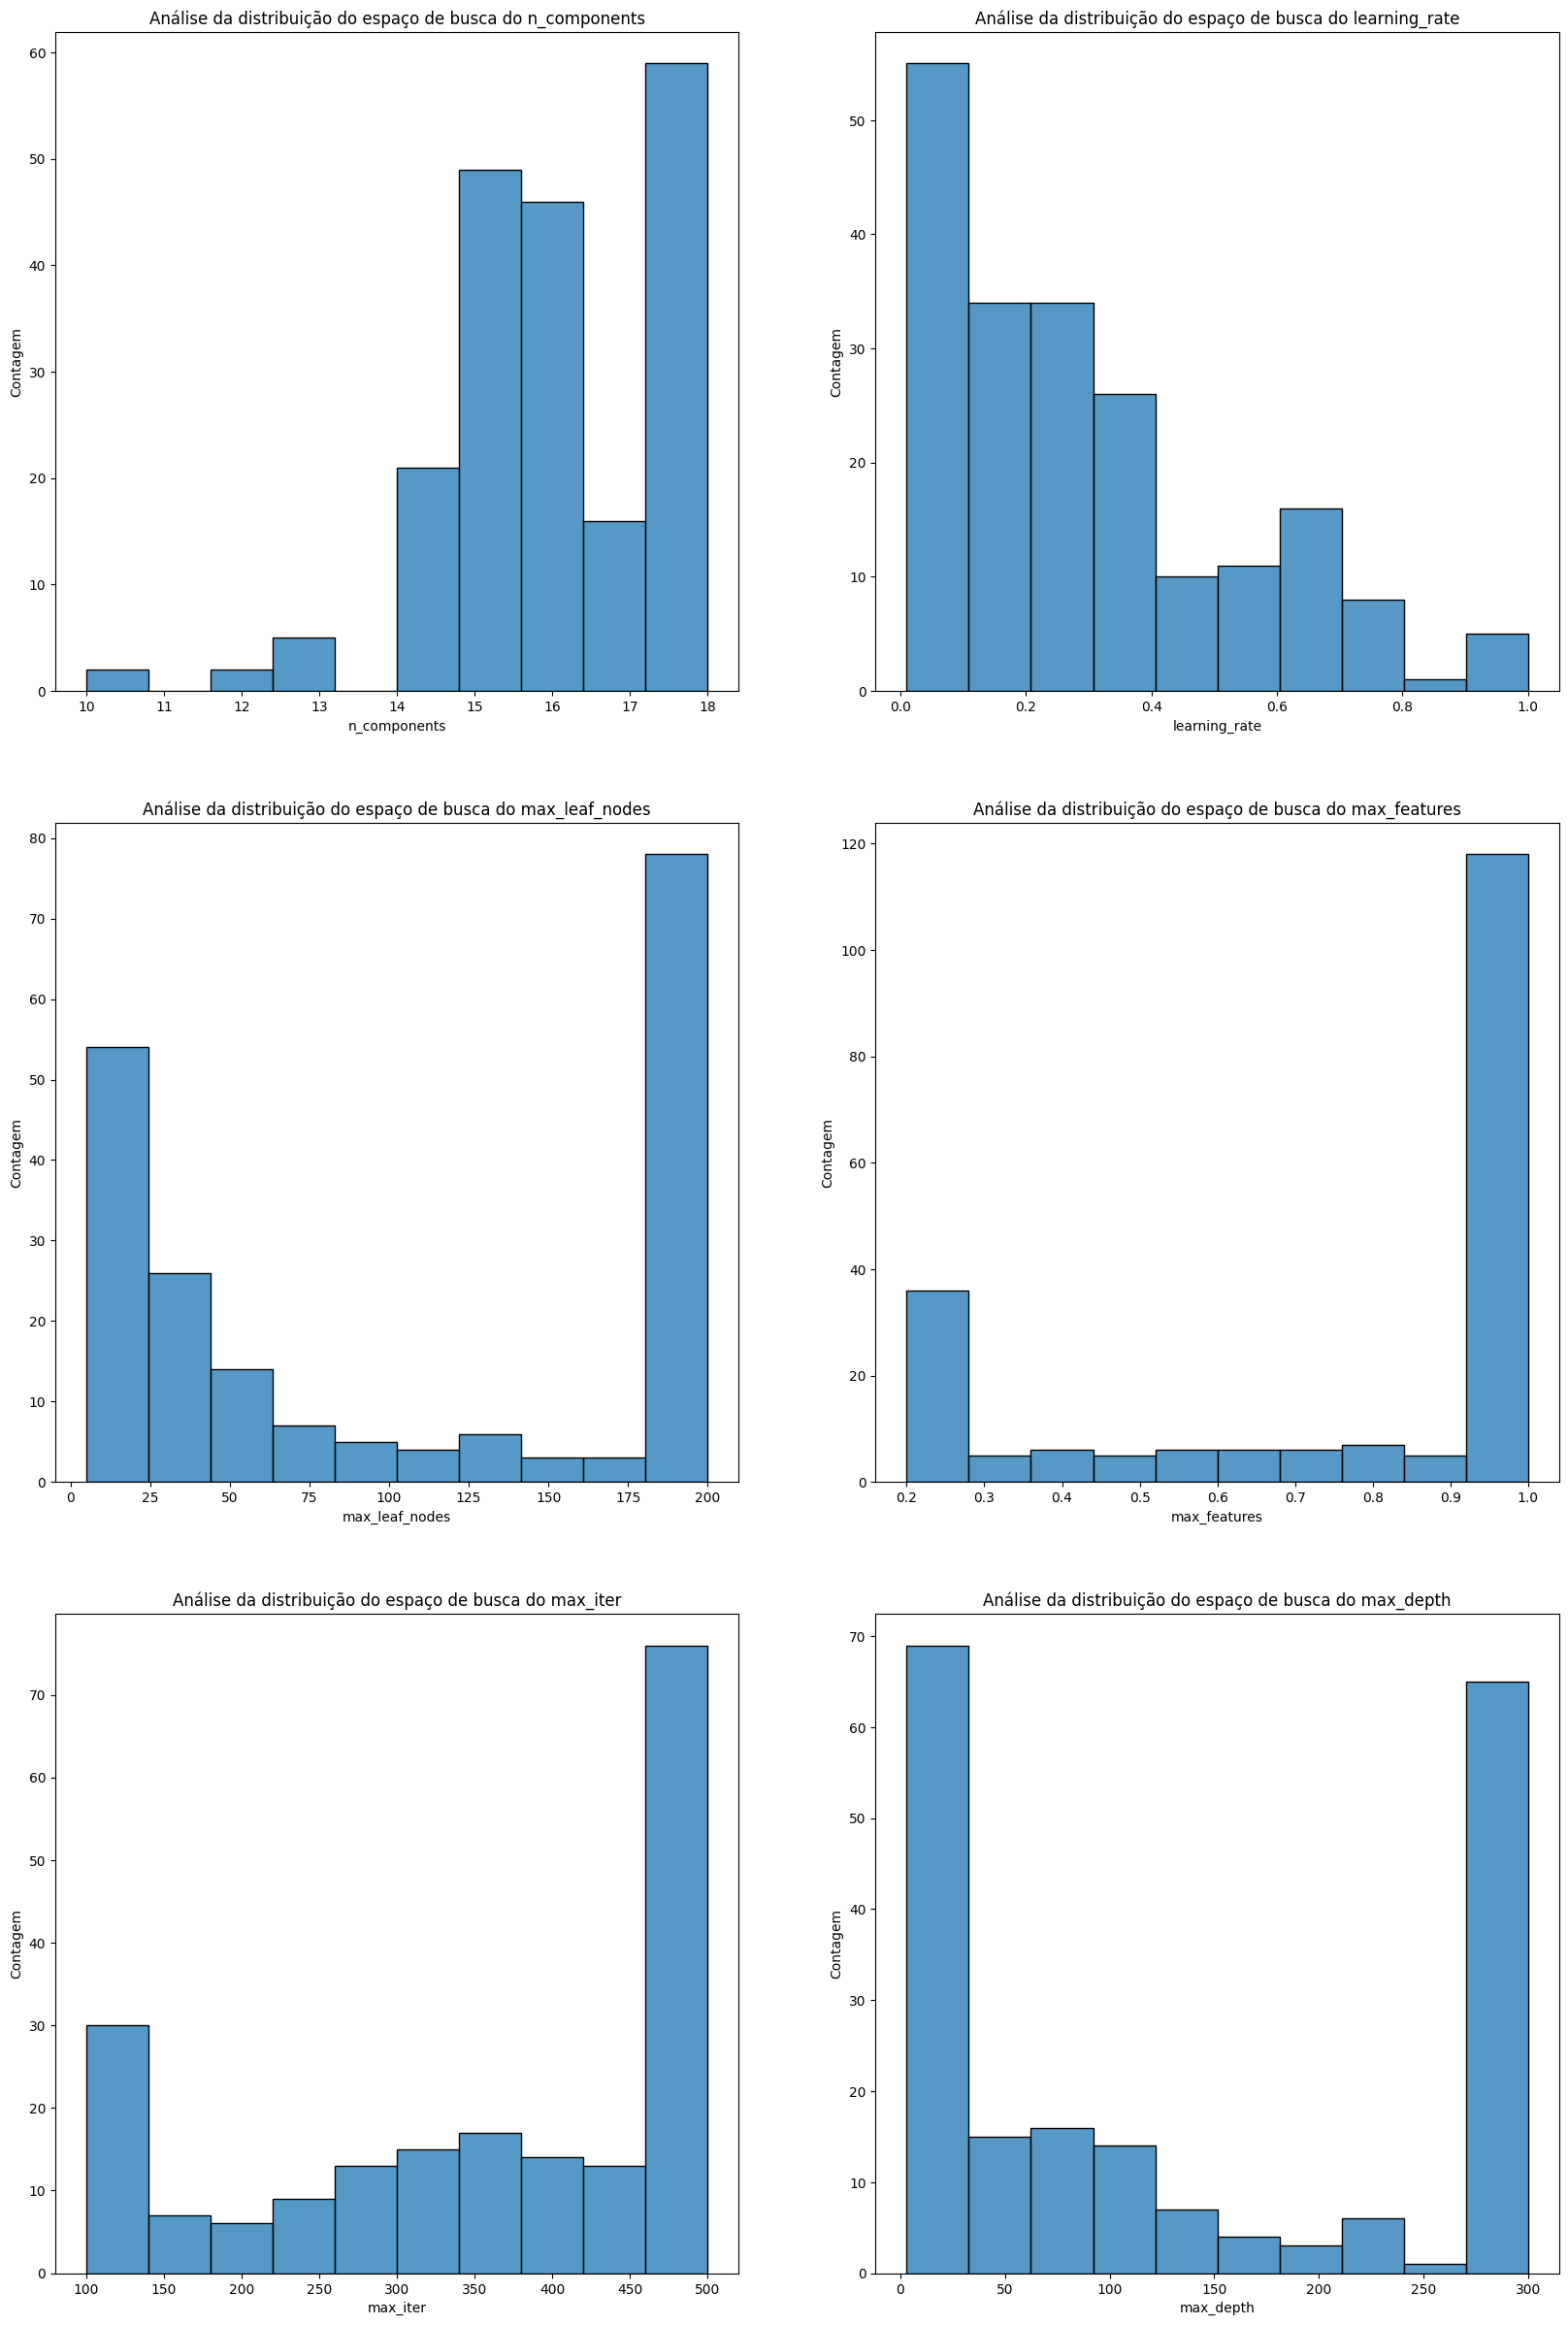

In [32]:
HYPERPARMS_ANALISYS = [
    "params_n_components",
    "params_learning_rate",
    "params_max_leaf_nodes",
    "params_max_features",
    "params_max_iter",
    "params_max_depth"
]

figs, axis = plt.subplots(nrows=3, ncols=2, figsize=(20, 30))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1]
]

for hyperparam, pos in zip(HYPERPARMS_ANALISYS, eixos):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        df[hyperparam],
        bins=10,
        ax=ax
    )

    hyperparam = hyperparam.replace("params_", "")
    ax.set_title(f"Análise da distribuição do espaço de busca do {hyperparam}")
    ax.set_xlabel(hyperparam)
    ax.set_ylabel("Contagem")

Obtivemos alguns resultados interessantes. Primeiro, que ``n_components`` se concentrou ainda mais em 15 e 16, o que aponta que valores fora disso ou adicionam informações que geram *overfitting* ou deixam o modelo simples demais. Além disso, ``learning_rate`` segue uma curva interessante, o que pode significar que um intervalo de 0.1 a 0.4 já pode ser um valor ótimo, sem muita necessidade de precisão, mas mantendo nesse intervalo.

Quanto aos hiperparâmetros com menos importância, vemos que ``max_leaf_nodes`` teve uma distribuição interessante, que pode apontar para um estudo mais fundo, uma vez que tivemos uma distribuição parecida com um decaimento exponencial, até que explode em 200. Isso poderia significar um simples efeito do GPSampler, mas esse *foi o valor do **melhor trial***, o que pode significar que (1) esse não é um hiperparâmetro que afete tanto o desempenho, ou (2) ele tem algo que ainda não foi analisado com completude. Mas a melhor aposta, pelo resultado da importância atribuida a cada hiperparâmetro, aponta para a 1ª hipótese.

Algo interessante acontece com ``max_feature``, ele usa muitos valores do limite superior do espaço de busca, mas o melhor valor ainda foi dentro do previsto anteriormente. Isso pode apontar para um efeito do GPSampler novamente, mas uma concentração tão grande em 1.0 e tão pequena no resto - incluindo no limite inferior - pode exigir melhor análise.

``max_iter`` teve resultados semelhantes a ``max_leaf_nodes``, então seria necessário uma análise mais profunda. Já ``max_depth`` foi extremamente interessante, uma vez que teve uma distribuição relativamente grande entre 50 e 100, algo esperado pelos resultados anteriores, mas ainda assim com grandes concentraçõe nos limites, o que provavelmente seria causado pelo GPSampler também.

## Análise **Naive-Bayes Gaussiano**

Primeiro vamos carregar o estudo.

In [33]:
NOME_DO_ESTUDO = "YSO_classifier-Naive_Bayes_v2"
objeto_de_estudo_NB = load_study(
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
)

df = objeto_de_estudo_NB.trials_dataframe()

Agora vamos ver o melhor *trial*.

In [34]:
melhor_trial = objeto_de_estudo_NB.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

melhor_trial = df["number"] == melhor_trial.number
df.loc[melhor_trial]["value"]

Número do melhor trial: 6
Parâmetros do melhor trial: {'var_smoothing': 1.243535478064173e-06}


6    0.883177
Name: value, dtype: float64

Algo extremamente interessante como resultado, o melhor *trial* foi o de número 6, ou seja, ele convergiu extremamente rápido. Isso mostra o real poder preditivo desse algoritmo, que é simples, mas eficiente. Porém, mesmo assim, seu poder de predição foi relativamente menor em comparação aos outros. A partir disso, o ideal a se fazer é ter um balanço, assim como para outros algoritmos, entre poder preditivo e *custo computacional*, algo que ainda não foi levado tão em conta ainda. Isso porque esse algoritmo treina *extremamente rápido*, e isso pesa quando falamos de astronomia, que significa uma gama imensa de dados.